# Data-Quality and Reproducibility Audit of My Own Data
### Tissue parent-roll imports, Peru 2020–2025 (Veritrade / SUNAT) — Angela Milén Acosta Ticona (UNMSM)

**Thesis title:** Sustainable Import Patterns of Tissue Parent Rolls in Peru (2020–2025): A Machine Learning Analysis of Customs Import Records.
**Problem:** customs records have no environmental field, so sustainability must be measured with text proxies; before any model, the data themselves must be audited.

In Session 6 I audited the reproducibility of a published paper (DATE, Kim et al., KDD 2020) on its synthetic data. This notebook applies
the same questions **to my own data and pipeline**:

| Audit question | Section |
|---|---|
| Is every data version identified and unchanged? | 1 |
| What is the quality of the raw data (completeness, uniqueness, validity, consistency)? | 2 |
| Can the cleaning be re-run and give exactly the final file? | 3 |
| Are anomalies detected consistently? | 4 |
| Are the results stable across **20 seeds**? | 5 |
| What happens without seeds (the DATE lesson)? | 6 |
| Do the Session 6 traps (leakage, twins, significance without size) affect **my** results? | 7 |
| How does my own work score on the Session 6 reproducibility scorecard? | 9 |

> **ES:** En la Sesión 6 audité un artículo publicado (DATE). Aquí aplico la misma auditoría a **mis propios datos**: calidad de los datos,
> limpieza reproducible, anomalías y estabilidad con 20 semillas.

## 0. Environment

In [1]:
import hashlib, os, platform, re, sys, time, unicodedata, warnings
T0 = time.time()
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd, sklearn, matplotlib, matplotlib.pyplot as plt, xgboost

SEED = 42
DATA, FIG, OUT = Path('data'), Path('figures'), Path('outputs')
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)
BLUE, ORANGE, INK, MUTED, SURFACE = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#fcfcfb'
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'axes.edgecolor': '#c9c8c3',
                     'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.grid': True,
                     'grid.color': '#e6e5e0', 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.axisbelow': True, 'font.size': 10, 'axes.titleweight': 'bold'})
for lib in (np, pd, sklearn, xgboost, matplotlib):
    print(f'{lib.__name__:12s} {lib.__version__}')
print('python      ', platform.python_version())
print('machine     ', platform.platform(), '|', os.cpu_count(), 'CPU cores | no GPU')

numpy        2.5.3
pandas       3.0.5
sklearn      1.9.1
xgboost      3.4.1
matplotlib   3.11.2
python       3.13.16
machine      Linux-6.18.44-fc-v185-x86_64-with-glibc2.39 | 2 CPU cores | no GPU


## 1. Data versions and fingerprints
Three versions of the data exist. Each one is identified by its MD5 hash; the notebook stops if any file differs from the registered version.

| Version | Content | Produced by |
|---|---|---|
| 01 raw | Veritrade export, all lines of HS 4803.00.90, 4818.20, 4818.90 | Veritrade download |
| 02 prefiltered | Lines kept after my manual first pass | Me (domain expert) |
| 03 final | Parent rolls (*bobinas*) for conversion | `limpieza_reglas.py` + `decisiones_manuales.csv` |
> **ES:** Cada versión de los datos tiene su "huella digital" (MD5). Si alguien cambia una celda, la huella cambia y el notebook se detiene.

In [2]:
REGISTERED = {'01_raw_veritrade.xlsx': 'f80dfc93bd7849ce7eb762317f154682',
              '02_prefiltered.xlsx':  '9db059eda20d8ec3b574817c0a828145',
              '03_final_bobinas.xlsx': 'f2d7e5e54cc455749e50e57bb96dbfea'}
for f, h in REGISTERED.items():
    got = hashlib.md5((DATA / f).read_bytes()).hexdigest()
    print(f'{f:24s} {got}  {"OK" if got == h else "CHANGED"}')
    assert got == h

def read_veritrade(f):                       # Veritrade exports have 5 title rows
    d = pd.read_excel(DATA / f, header=5)
    return d[d['Partida Aduanera'].notna()].reset_index(drop=True)
raw, pre = read_veritrade('01_raw_veritrade.xlsx'), read_veritrade('02_prefiltered.xlsx')
fin = pd.read_excel(DATA / '03_final_bobinas.xlsx').sort_values(['Fecha', 'DUA / DAM']).reset_index(drop=True)
print(f'\nrecords: raw {len(raw):,} | prefiltered {len(pre):,} | final {len(fin):,}')

01_raw_veritrade.xlsx    f80dfc93bd7849ce7eb762317f154682  OK
02_prefiltered.xlsx      9db059eda20d8ec3b574817c0a828145  OK
03_final_bobinas.xlsx    f2d7e5e54cc455749e50e57bb96dbfea  OK



records: raw 11,586 | prefiltered 3,748 | final 2,994


## 2. Data-quality audit
Four standard dimensions, measured on the raw export and on the final file:
**completeness** (missing values), **uniqueness** (duplicates), **validity** (values inside their allowed domain) and
**consistency** (fields that must agree with each other).
> **ES:** Medimos la calidad en cuatro dimensiones: datos faltantes, duplicados, valores fuera de rango y campos que se contradicen.

In [3]:
def is_missing(s):
    s2 = s.astype(str).str.strip().str.upper()
    return s.isna() | s2.isin(['', 'NAN', 'NO DISPONIBLE', '_X0000_'])

def quality(d):
    r = {}
    for col, label in [('Importador', 'importer'), ('Embarcador / Exportador', 'supplier'), ('Pais de Origen', 'origin country'),
                       ('Canal', 'inspection channel'), ('Descripcion Comercial', 'commercial description'),
                       ('Kg Neto', 'net kg'), ('U$ FOB Tot', 'FOB value')]:
        r[('Completeness', f'{label} missing')] = is_missing(d[col]).sum()
    r[('Uniqueness', 'exact duplicate rows')] = d.duplicated().sum()
    r[('Uniqueness', 'same DAM + HS + description + kg')] = d.duplicated(['DUA / DAM', 'Partida Aduanera', 'Descripcion Comercial', 'Kg Neto']).sum()
    r[('Validity', 'net kg <= 0')] = (d['Kg Neto'] <= 0).sum()
    r[('Validity', 'FOB value <= 0')] = (d['U$ FOB Tot'] <= 0).sum()
    r[('Validity', 'date outside 2020-2025')] = (~d.Fecha.dt.year.between(2020, 2025)).sum()
    r[('Validity', 'HS code outside the 3 queried')] = (~d['Partida Aduanera'].isin([4803009000, 4818200000, 4818900000])).sum()
    r[('Validity', 'channel not VERDE/NARANJA/ROJO')] = (~d['Canal'].isin(['VERDE', 'NARANJA', 'ROJO'])).sum()
    if 'Kg Bruto' in d:
        r[('Consistency', 'gross kg < net kg')] = (d['Kg Bruto'] < d['Kg Neto']).sum()
    r[('Consistency', 'CIF value < FOB value')] = (d['U$ CIF Tot'] < d['U$ FOB Tot']).sum()
    uv = d['U$ FOB Tot'] / d['Kg Neto']
    r[('Consistency', 'FOB per kg outside 0.3–5 US$')] = (~uv.between(0.3, 5)).sum()
    return pd.Series(r)

dq = pd.DataFrame({'raw (n)': quality(raw), 'final (n)': quality(fin)})
dq['raw %'] = (100 * dq['raw (n)'] / len(raw)).round(2)
dq['final %'] = (100 * dq['final (n)'] / len(fin)).round(2)
dq.index.names = ['dimension', 'check']
dq.to_csv(OUT / 'table1_data_quality.csv')
dq

raw (n)  final (n)  raw %  \
dimension    check                                                         
Completeness FOB value missing                       0        0.0   0.00   
             commercial description missing          0        0.0   0.00   
             importer missing                       64        1.0   0.55   
             inspection channel missing            201       18.0   1.73   
             net kg missing                          0        0.0   0.00   
             origin country missing                  0        0.0   0.00   
             supplier missing                     3154     1448.0  27.22   
Consistency  CIF value < FOB value                   0        0.0   0.00   
             FOB per kg outside 0.3–5 US$         2894        4.0  24.98   
             gross kg < net kg                       0        NaN   0.00   
Uniqueness   exact duplicate rows                    0        0.0   0.00   
             same DAM + HS + description + kg        0        0.0   0.00   
Validity     FOB value <= 0                          1        0.0   0.01   
             HS code outside the 3 queried           0        0.0   0.00   
             channel not VERDE/NARANJA/ROJO        201       18.0   1.73   
             date outside 2020-2025                  0        0.0   0.00   
             net kg <= 0                             7        0.0   0.06   

                                               final %  
dimension    check                                      
Completeness FOB value missing                    0.00  
             commercial description missing       0.00  
             importer missing                     0.03  
             inspection channel missing           0.60  
             net kg missing                       0.00  
             origin country missing               0.00  
             supplier missing                    48.36  
Consistency  CIF value < FOB value                0.00  
             FOB per kg outside 0.3–5 US$         0.13  
             gross kg < net kg                     NaN  
Uniqueness   exact duplicate rows                 0.00  
             same DAM + HS + description + kg     0.00  
Validity     FOB value <= 0                       0.00  
             HS code outside the 3 queried        0.00  
             channel not VERDE/NARANJA/ROJO       0.60  
             date outside 2020-2025               0.00  
             net kg <= 0                          0.00

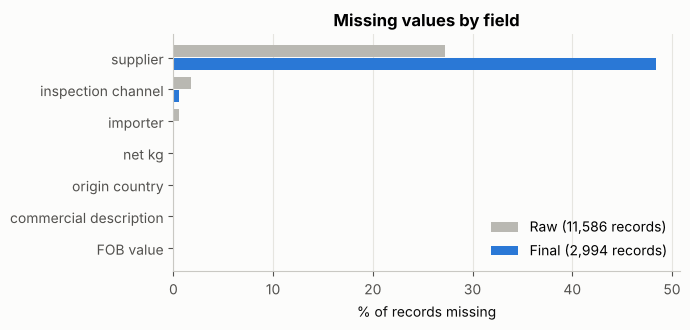

In [4]:
comp = dq.loc['Completeness'][['raw %', 'final %']].sort_values('raw %')
fig, ax = plt.subplots(figsize=(7, 3.4))
y = np.arange(len(comp))
ax.barh(y + 0.2, comp['raw %'], height=0.38, color='#b9b8b2', label=f'Raw ({len(raw):,} records)')
ax.barh(y - 0.2, comp['final %'], height=0.38, color=BLUE, label=f'Final ({len(fin):,} records)')
ax.set_yticks(y, [i.replace(' missing', '') for i in comp.index])
ax.set(title='Missing values by field', xlabel='% of records missing')
ax.legend(frameon=False, loc='lower right'); ax.grid(axis='y', visible=False)
fig.tight_layout(); fig.savefig(FIG / 'fig1_missing.png', dpi=200)

**Reading the audit (filled in from the outputs above):** the supplier is the weakest field — it is missing in a large share of
records, so the thesis does not use supplier identity as a predictor, only a *supplier reported yes/no* flag. Records with an
inconsistent FOB/kg are not deleted; they are handled by the anomaly screen (Section 4) and the sensitivity analysis.
> **ES:** El proveedor es el campo más débil (falta en casi la mitad de los registros). Por eso no se usa como variable,
> solo un indicador de si está reportado o no.

## 3. Data lineage: can the cleaning be re-run?
The step from the prefiltered file to the final file is pure code: written rules (`limpieza_reglas.py`) plus documented expert
decisions (`decisiones_manuales.csv`). Here the rules are re-applied from scratch and the result is compared, record by record,
with the registered final file.
> **ES:** Volvemos a ejecutar la limpieza desde cero y comprobamos que se obtiene exactamente el archivo final, registro por registro.

In [5]:
sys.path.insert(0, '.')
from limpieza_reglas import classify
DESC = ['Descripcion Comercial'] + [f'Descripcion{i}' for i in range(1, 6)]
norm = lambda s: unicodedata.normalize('NFKD', s).encode('ascii', 'ignore').decode().upper()
txt = pre[DESC].fillna('').astype(str).agg(' | '.join, axis=1).map(norm)
res = txt.map(classify)
pre['decision'] = res.str[0].map({'KEEP': 'keep (rule)', 'REMOVE': 'remove (rule)', 'REVIEW': 'review'})
pre['reason'] = res.str[1]

man = pd.read_csv('decisiones_manuales.csv', dtype=str)
key = lambda d: d['DUA / DAM'].astype(str) + '|' + d['Partida Aduanera'].astype(str).str[:10]
yes = set(key(man[man.Decision.str.upper() == 'SI']))
k_pre = key(pre)
pre.loc[(pre.decision == 'review') & k_pre.isin(yes), 'decision'] = 'keep (expert)'
pre.loc[pre.decision == 'review', 'decision'] = 'excluded (unresolved review)'

rebuilt = pre[pre.decision.str.startswith('keep')]
rid = lambda d: d['DUA / DAM'].astype(str) + '|' + d['Partida Aduanera'].astype(str) + '|' + d['Descripcion Comercial'].astype(str) + '|' + d['Kg Neto'].astype(str)
same = set(rid(rebuilt)) == set(rid(fin)) and len(rebuilt) == len(fin)
print(f'Rebuilt {len(rebuilt):,} records; registered final file {len(fin):,}; identical record set: {same}')
assert same

lineage = pd.DataFrame([
    ('01 raw Veritrade export', len(raw), ''),
    ('02 after my manual first pass', len(pre), f'-{len(raw) - len(pre):,} lines outside the parent-roll focus'),
] + [(f'   {k}', v, '') for k, v in pre.decision.value_counts().items()] + [
    ('03 final parent-roll file', len(fin), 'keep (rule) + keep (expert)')], columns=['step', 'records', 'note'])
lineage.to_csv(OUT / 'table2_lineage.csv', index=False)
lineage

Rebuilt 2,994 records; registered final file 2,994; identical record set: True


,step,records,note
0,01 raw Veritrade export,11586,
1,02 after my manual first pass,3748,"-7,838 lines outside the parent-roll focus"
2,keep (rule),2968,
3,remove (rule),704,
4,excluded (unresolved review),50,
5,keep (expert),26,
6,03 final parent-roll file,2994,keep (rule) + keep (expert)


In [6]:
reasons = pre[pre.decision == 'remove (rule)'].reason.str.extract(r'^([^:"]+)')[0].str.strip().value_counts()
reasons.rename('records removed').to_frame()

,records removed
0,
producto terminado/empacado,385
no es papel para conversion,280
producto de consumo sin medidas de bobina,35
diametro 18.5 cm,1
diametro 30 cm,1
diametro 33 cm,1
diametro 9 cm,1


## 4. Anomaly screen and its stability
Isolation Forest (2% contamination) on log net kg, log FOB/kg and grammage. Because the method is random, it is run with **20 seeds**
and the overlap of the flagged sets is measured (Jaccard index: 1 = identical sets).
> **ES:** El detector de anomalías tiene azar. Lo ejecutamos con 20 semillas y medimos si marca siempre los mismos registros.

In [7]:
from sklearn.ensemble import IsolationForest
t_fin = fin[DESC].fillna('').astype(str).agg(' '.join, axis=1).map(norm)
def gsm(t):
    m = re.search(r'(?:GSM|G/M2|GRAMAJE|SUB(?:STANCE)?|BASIS(?:\s+GSM)?)\s*[:=]?\s*(\d{2}(?:[.,]\d+)?)', t) or \
        re.search(r'(\d{2}(?:[.,]\d+)?)\s*(?:GSM|G/M2|GRS?\b|GRAMOS|G\b)', t)
    v = float(m.group(1).replace(',', '.')) if m else np.nan
    return v if 10 <= v <= 60 else np.nan
g = t_fin.map(gsm)
kg, fob = fin['Kg Neto'].round(2), fin['U$ FOB Tot'].round(2)          # same rounding as the public feature table
X = pd.DataFrame({'log_kg': np.log10(kg), 'log_usd_kg': np.log10(fob / kg),
                  'gsm': g.fillna(g.median())})
flags = {s: set(np.where(IsolationForest(n_estimators=300, contamination=0.02, random_state=s).fit_predict(X) == -1)[0])
         for s in range(20)}
jac = [len(flags[a] & flags[b]) / len(flags[a] | flags[b]) for a in range(20) for b in range(a + 1, 20)]
core = set.intersection(*flags.values())
print(f'flagged per seed: {len(flags[0])} | mean pairwise Jaccard = {np.mean(jac):.3f} (min {np.min(jac):.3f})')
print(f'{len(core)} records are flagged by all 20 seeds (stable core of anomalies)')

flagged per seed: 59 | mean pairwise Jaccard = 0.764 (min 0.558)
39 records are flagged by all 20 seeds (stable core of anomalies)


**Reading:** the flagged sets overlap well but not perfectly across seeds (mean Jaccard below 0.8): records near the boundary
change with the seed. Therefore the thesis does not treat "anomaly" as a fixed label from one seed; it uses the **stable core**
(records flagged by all 20 seeds) for profiling and reports results with and without anomalies.
> **ES:** El detector no marca exactamente los mismos registros con cada semilla. Por eso usamos solo el "núcleo estable":
> los registros marcados por las 20 semillas.

## 5. Stability of the main result across 20 seeds
The RQ2 model (logistic regression, 5-fold cross-validation grouped by importer, PR-AUC) and the RQ1 profiles (K-Means, k = 6)
are re-run with seeds 0–19. Same pipeline as the public repository `repro-lab-roll-paper`.
> **ES:** Repetimos el modelo principal y los perfiles con 20 semillas. Si el resultado casi no cambia, es estable.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, adjusted_rand_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.cluster import KMeans

m = pd.DataFrame({'hs': fin['Partida Aduanera'].astype(str).str[:6], 'customs_office': fin['Aduana'].fillna('NA'),
                  'transport': fin['Via'].fillna('NA'), 'channel': fin['Canal'].fillna('NOT RECORDED'),
                  'month': fin.Fecha.dt.month, 'gsm': g, 'log_kg': X.log_kg, 'log_usd_kg': X.log_usd_kg,
                  'supplier_known': fin['Embarcador / Exportador'].replace('NO DISPONIBLE', np.nan).notna().astype(int)})
top = fin['Pais de Origen'].value_counts().index[:8]
m['origin'] = fin['Pais de Origen'].where(fin['Pais de Origen'].isin(top), 'OTHER')
m['product'] = np.select([t_fin.str.contains('TOALLA|TOWEL'), t_fin.str.contains('HIGIENICO|TOILET|BATH'),
                          t_fin.str.contains('SERVILLETA|NAPKIN')], ['towel', 'toilet', 'napkin'], 'other')
y = (t_fin.str.contains(r'\bFSC\b|\bPEFC\b|ISO\s*14001|ECO.?LABEL') | t_fin.str.contains('RECICLAD|RECYCL')).astype(int)
imp = fin['Importador'].fillna('NO DISPONIBLE').astype(str).str.strip()
groups = imp.map({v: f'IMP_{i+1:03d}' for i, v in enumerate(pd.unique(imp))})   # same anonymous codes as the public repository
CAT, NUM = ['hs', 'origin', 'customs_office', 'transport', 'channel', 'product'], ['log_kg', 'log_usd_kg', 'gsm', 'supplier_known', 'month']

def lr_prauc(seed):
    sc = []
    for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=seed).split(m, y, groups):
        p = Pipeline([('pre', ColumnTransformer([('c', OneHotEncoder(handle_unknown='ignore', min_frequency=10), CAT),
                                                ('n', Pipeline([('i', SimpleImputer(strategy='median')), ('s', StandardScaler())]), NUM)])),
                      ('clf', LogisticRegression(max_iter=2000, class_weight='balanced', C=0.5))]).fit(m.iloc[tr], y.iloc[tr])
        sc.append(average_precision_score(y.iloc[te], p.predict_proba(m.iloc[te])[:, 1]))
    return np.mean(sc)

seeds = list(range(20))
pr = pd.Series({s: lr_prauc(s) for s in seeds}, name='PR-AUC')
assert lr_prauc(7) == pr[7]                      # same seed -> identical result
print(f'RQ2 logistic regression, 20 seeds: PR-AUC = {pr.mean():.4f} ± {pr.std(ddof=1):.4f} (range {pr.min():.3f}–{pr.max():.3f}); base rate {y.mean():.4f}')

ok = ~fin.index.isin(list(core))                    # profiles on non-anomalous records
Xk = np.column_stack([StandardScaler().fit_transform(pd.DataFrame({'a': X.log_kg, 'b': X.log_usd_kg, 'c': X.gsm})[ok]),
                      pd.get_dummies(m['product'][ok], dtype=float)])
labels = {s: KMeans(6, n_init=20, random_state=s).fit_predict(Xk) for s in seeds}
ari = [adjusted_rand_score(labels[0], labels[s]) for s in seeds[1:]]
print(f'RQ1 K-Means (k = 6), 20 seeds: adjusted Rand index vs seed 0 = {np.mean(ari):.3f} (min {np.min(ari):.3f})')
pd.DataFrame({'seed': seeds, 'pr_auc': pr.values.round(5), 'kmeans_ari_vs_seed0': [1.0] + [round(a, 4) for a in ari]}) \
  .to_csv(OUT / 'table3_seed_stability.csv', index=False)

RQ2 logistic regression, 20 seeds: PR-AUC = 0.4686 ± 0.0212 (range 0.421–0.517); base rate 0.0444


RQ1 K-Means (k = 6), 20 seeds: adjusted Rand index vs seed 0 = 0.971 (min 0.958)


## 6. The DATE lesson: what happens without seeds?
In the DATE audit, the same code gave Precision@1% between 15.8% and 34.7% when re-run without seeds. Here the same experiment is
done on my data with XGBoost (which uses random subsampling): five runs **with** a fixed seed and five runs **without** one
(the seed is drawn from the system clock, as happens when no seed is set).
> **ES:** Repetimos la prueba que hicimos con DATE: con semilla fija el resultado es idéntico; sin semilla, cambia en cada ejecución.
> *Nota:* esta celda da números distintos cada vez que se ejecuta **a propósito**; ese es el hallazgo.

with seed 42  : [0.456 0.456 0.456 0.456 0.456] -> identical
without seed  : [0.4868 0.4714 0.4111 0.4199 0.3916] -> range 0.392–0.487


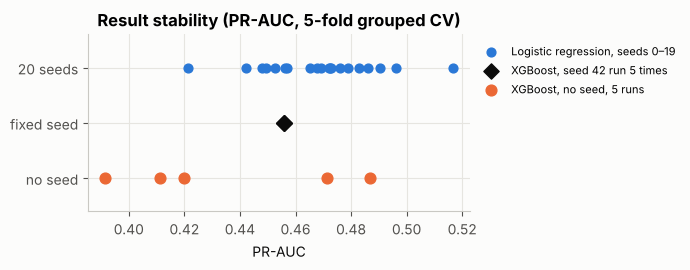

In [9]:
from xgboost import XGBClassifier
Xo = Pipeline([('pre', ColumnTransformer([('c', OneHotEncoder(handle_unknown='ignore', min_frequency=10), CAT),
                                          ('n', SimpleImputer(strategy='median'), NUM)]))]).fit_transform(m)
def xgb_run(seed):
    folds = StratifiedGroupKFold(5, shuffle=True, random_state=seed).split(m, y, groups)
    sc = []
    for tr, te in folds:
        clf = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                            scale_pos_weight=(y.iloc[tr] == 0).sum() / y.iloc[tr].sum(), random_state=seed, n_jobs=1)
        sc.append(average_precision_score(y.iloc[te], clf.fit(Xo[tr], y.iloc[tr]).predict_proba(Xo[te])[:, 1]))
    return np.mean(sc)

seeded = [xgb_run(SEED) for _ in range(5)]
unseeded = [xgb_run(int(np.random.SeedSequence().entropy % 2**31)) for _ in range(5)]
print('with seed 42  :', np.round(seeded, 4), '-> identical' if len(set(seeded)) == 1 else '-> DIFFERENT')
print('without seed  :', np.round(unseeded, 4), f'-> range {min(unseeded):.3f}–{max(unseeded):.3f}')

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.scatter(pr.values, np.full(20, 2), s=40, color=BLUE, label='Logistic regression, seeds 0–19')
ax.scatter(seeded, np.full(5, 1), s=60, color=INK, marker='D', label='XGBoost, seed 42 run 5 times')
ax.scatter(unseeded, np.full(5, 0), s=60, color=ORANGE, label='XGBoost, no seed, 5 runs')
ax.set_yticks([0, 1, 2], ['no seed', 'fixed seed', '20 seeds']); ax.set_ylim(-0.6, 2.6)
ax.set(title='Result stability (PR-AUC, 5-fold grouped CV)', xlabel='PR-AUC')
ax.legend(frameon=False, fontsize=8, loc='upper left', bbox_to_anchor=(1, 1)); fig.tight_layout()
fig.savefig(FIG / 'fig2_seed_stability.png', dpi=200)

## 7. The Session 6 labs, repeated on my data
In Session 6 each lab exposed one trap with toy data. Here the same traps are tested on **my** parent-roll records.

| Lab | Trap | Question on my data |
|---|---|---|
| 2 · Leak detector | test information reaches training | What if the commercial description (where the label words live) is used as a feature? |
| 3 · Patient twins | the same unit in train and test | What if records of the same **importer** fall in both train and test? |
| 5 · Significant ≠ important | p-value without effect size | How big are my effects, with what interval? |
> **ES:** Repito los labs de la Sesión 6 con mis bobinas: fuga por la descripción, "importadores gemelos" y tamaño del efecto.

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedKFold

def make_lr(text=False):
    parts = [('c', OneHotEncoder(handle_unknown='ignore', min_frequency=10), CAT),
             ('n', Pipeline([('i', SimpleImputer(strategy='median')), ('s', StandardScaler())]), NUM)]
    if text:   # LEAKY: the description contains the very words that define the label
        parts.append(('t', TfidfVectorizer(min_df=3), 'desc'))
    return Pipeline([('pre', ColumnTransformer(parts)),
                     ('clf', LogisticRegression(max_iter=3000, class_weight='balanced', C=0.5))])

m['desc'] = t_fin
def cv_prauc(seed, grouped=True, text=False):
    splitter = StratifiedGroupKFold(5, shuffle=True, random_state=seed) if grouped else StratifiedKFold(5, shuffle=True, random_state=seed)
    sc = []
    for tr, te in splitter.split(m, y, groups if grouped else None):
        p = make_lr(text).fit(m.iloc[tr], y.iloc[tr])
        sc.append(average_precision_score(y.iloc[te], p.predict_proba(m.iloc[te])[:, 1]))
    return np.mean(sc)

lab = pd.DataFrame({
    'Clean: grouped by importer (my design)': [cv_prauc(s) for s in seeds],
    'Lab 3 trap: random split (importer twins)': [cv_prauc(s, grouped=False) for s in seeds],
    'Lab 2 trap: description used as a feature (leak)': [cv_prauc(s, text=True) for s in seeds]})
summary = lab.agg(['mean', 'std']).T.round(4)
summary.columns = ['PR-AUC mean (20 seeds)', 'SD']
summary.to_csv(OUT / 'table5_session6_traps.csv')
print(f'base rate (random guess) = {y.mean():.4f}')
summary

base rate (random guess) = 0.0444


,PR-AUC mean (20 seeds),SD
Clean: grouped by importer (my design),0.4686,0.0212
Lab 3 trap: random split (importer twins),0.5977,0.0116
Lab 2 trap: description used as a feature (leak),0.7941,0.0226


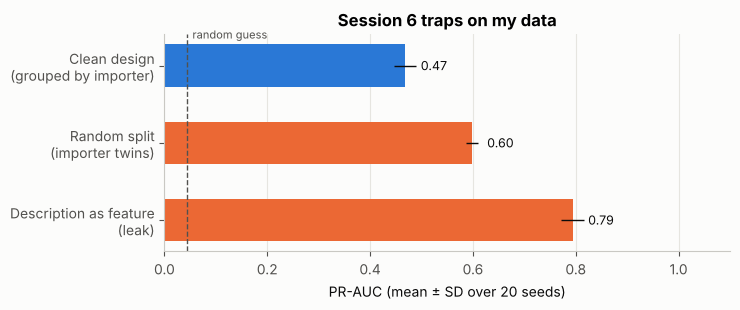

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
names = ['Clean design\n(grouped by importer)', 'Random split\n(importer twins)', 'Description as feature\n(leak)']
vals, sds = summary.iloc[:, 0].values, summary.iloc[:, 1].values
ax.barh(names[::-1], vals[::-1], xerr=sds[::-1], color=[ORANGE, ORANGE, BLUE], height=0.55, error_kw={'ecolor': INK, 'lw': 1})
ax.axvline(y.mean(), color=MUTED, ls='--', lw=1); ax.text(y.mean() + 0.01, 2.35, 'random guess', color=MUTED, fontsize=8)
for i, v in enumerate(vals[::-1]):
    ax.text(v + 0.03, i, f'{v:.2f}', va='center', color=INK, fontsize=9)
ax.set(xlim=(0, 1.1), xlabel='PR-AUC (mean ± SD over 20 seeds)', title='Session 6 traps on my data'); ax.grid(axis='y', visible=False)
fig.tight_layout(); fig.savefig(FIG / 'fig3_session6_traps.png', dpi=200)

**Reading:** using the description as a feature raises the score from 0.47 to about 0.79 — but the gain is fiction, because the label is built from words
in that same description (Lab 2). Mixing records of the same importer in train and test changes the score compared with my grouped design
(Lab 3); my results always use the grouped split, so they measure generalisation to **new importers**, not memory of known ones.
> **ES:** Si se usa la descripción como variable, el puntaje sube de 0.47 a 0.79, pero es ficción: la etiqueta sale de esas mismas palabras.
> Mezclar al mismo importador en entrenamiento y prueba cambia el resultado; mi diseño siempre separa por importador.

In [12]:
import statsmodels.formula.api as smf
from scipy import stats
rows = []

# (a) price: recycled-fibre vs virgin parent rolls (non-anomalous records)
virgin = t_fin.str.contains(r'VIRGEN|VIRGIN|\bPURE\b|\bPUR[AO]\b|100\s*%\s*CELULOSA')
recyc = t_fin.str.contains('RECICLAD|RECYCL')
d = pd.DataFrame({'lp': X.log_usd_kg * np.log(10), 'fibre': np.select([recyc, virgin], ['recycled', 'virgin'], 'other'),
                  'year': fin.Fecha.dt.year, 'product': m['product'], 'hs': m['hs']})[ok]
d = d[d.fibre != 'other']
ols = smf.ols('lp ~ C(fibre, Treatment("virgin")) + C(year) + C(product) + C(hs)', data=d).fit(cov_type='HC3')
k = [c for c in ols.params.index if 'recycled' in c][0]
b, (lo, hi) = ols.params[k], ols.conf_int().loc[k]
a, v = d.lp[d.fibre == 'recycled'], d.lp[d.fibre == 'virgin']
cohen_d = (a.mean() - v.mean()) / np.sqrt((a.var(ddof=1) + v.var(ddof=1)) / 2)
rows.append(('Price: recycled vs virgin (FOB/kg, adjusted)', f'{100*(np.exp(b)-1):+.1f}%',
             f'[{100*(np.exp(lo)-1):+.1f}%, {100*(np.exp(hi)-1):+.1f}%]', f"Cohen's d = {cohen_d:.2f}", f'{ols.pvalues[k]:.1e}'))

# (b) H5: share 2024-25 vs 2020-21
yr = fin.Fecha.dt.year
e, l = y[yr.isin([2020, 2021])], y[yr.isin([2024, 2025])]
diff = l.mean() - e.mean(); se = np.sqrt(l.mean()*(1-l.mean())/len(l) + e.mean()*(1-e.mean())/len(e))
h = 2*np.arcsin(np.sqrt(l.mean())) - 2*np.arcsin(np.sqrt(e.mean()))
rows.append(('H5: sustainable share 2024-25 minus 2020-21', f'{100*diff:+.2f} pts', f'[{100*(diff-1.96*se):+.2f}, {100*(diff+1.96*se):+.2f}] pts',
             f"Cohen's h = {h:.2f}", f'{stats.norm.sf(diff/se):.2f} (one-sided)'))

# (c) the model score also needs an interval: bootstrap of out-of-fold predictions (seed 42)
oof = np.zeros(len(y))
for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(m, y, groups):
    oof[te] = make_lr().fit(m.iloc[tr], y.iloc[tr]).predict_proba(m.iloc[te])[:, 1]
rng = np.random.default_rng(SEED)
boot = [average_precision_score(y.values[i], oof[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(2000))]
blo, bhi = np.percentile(boot, [2.5, 97.5])
rows.append(('Model PR-AUC, pooled out-of-fold (seed 42)', f'{average_precision_score(y, oof):.3f}', f'[{blo:.3f}, {bhi:.3f}] bootstrap',
             f'{average_precision_score(y, oof)/y.mean():.1f}× the base rate', 'n/a'))
effects = pd.DataFrame(rows, columns=['result', 'effect', '95% CI', 'effect size', 'p-value'])
effects.to_csv(OUT / 'table6_effect_sizes.csv', index=False)
effects

,result,effect,95% CI,effect size,p-value
0,"Price: recycled vs virgin (FOB/kg, adjusted)",-14.6%,"[-16.9%, -12.3%]",Cohen's d = -0.68,5.1e-30
1,H5: sustainable share 2024-25 minus 2020-21,-0.66 pts,"[-2.42, +1.10] pts",Cohen's h = -0.03,0.77 (one-sided)
2,"Model PR-AUC, pooled out-of-fold (seed 42)",0.436,"[0.352, 0.528] bootstrap",9.8× the base rate,n/a


**Reading (Lab 5: effect size, then CI, then p-value):** the price gap is large *and* precise (its interval excludes zero). It is
slightly larger here (about −15%) than in the analysis notebook (−13%) because here only virgin vs recycled records are compared and the
39 stable anomalies are excluded; both versions agree on the direction and on a medium effect size. For H5 the
interval includes zero and the effect size is tiny, so the honest sentence is "no detectable change", not "proof of no change".
The model's score is reported with a bootstrap interval, not as a single number.
> **ES:** Primero el tamaño del efecto, luego el intervalo y al final el valor p. El precio muestra una diferencia grande y precisa;
> para H5 el intervalo incluye el cero, así que la frase honesta es "no se detecta cambio".

## 8. Audit checklist

In [13]:
checklist = pd.DataFrame([
    ('Data versions fingerprinted (MD5) and verified', 'PASS'),
    ('Data-quality audit on 4 dimensions, raw vs final', 'PASS'),
    ('Cleaning re-run from code reproduces the final file exactly', 'PASS' if same else 'FAIL'),
    ('Expert decisions documented in a file, not done by hand', 'PASS'),
    (f'Anomaly screen stable across 20 seeds (mean Jaccard {np.mean(jac):.2f})', 'PASS' if np.mean(jac) > 0.8 else 'CHECK'),
    (f'Main result stable across 20 seeds (SD {pr.std(ddof=1):.3f})', 'PASS' if pr.std(ddof=1) < 0.05 else 'CHECK'),
    (f'Profiles stable across 20 seeds (mean ARI {np.mean(ari):.2f})', 'PASS' if np.mean(ari) > 0.8 else 'CHECK'),
    ('Same seed gives identical result', 'PASS' if len(set(seeded)) == 1 else 'FAIL'),
    ('Firm names never shown in outputs', 'PASS'),
], columns=['check', 'result'])
checklist.to_csv(OUT / 'table4_checklist.csv', index=False)
checklist

,check,result
0,Data versions fingerprinted (MD5) and verified,PASS
1,"Data-quality audit on 4 dimensions, raw vs final",PASS
2,Cleaning re-run from code reproduces the final...,PASS
3,"Expert decisions documented in a file, not don...",PASS
4,Anomaly screen stable across 20 seeds (mean Ja...,CHECK
5,Main result stable across 20 seeds (SD 0.021),PASS
6,Profiles stable across 20 seeds (mean ARI 0.97),PASS
7,Same seed gives identical result,PASS
8,Firm names never shown in outputs,PASS


## 9. My own work on the Session 6 reproducibility scorecard (slide 40)
The scorecard used to audit the DATE paper, now applied to **my** study: Yes = 1, Partial = 0.5, No = 0, with the evidence for each answer.
> **ES:** La misma lista de 9 puntos con la que audité el artículo DATE, aplicada ahora a **mi** estudio.

In [14]:
card = pd.DataFrame([
    ('Seeds reported, many runs?', 'Yes', 'Mean ± SD over 20 seeds for every model (Sections 5 and 7)'),
    ('Splits described?', 'Yes', '5-fold cross-validation grouped by importer; temporal hold-out 2025 in the analysis notebook'),
    ('Leakage checked?', 'Yes', 'Preprocessing inside Pipelines; description excluded as a feature (Lab 2 shows the leak it avoids); grouped split (Lab 3)'),
    ('Tuning separated?', 'Partial', 'Hyperparameters fixed in advance and never tuned on test data, but no nested cross-validation'),
    ('Statistical test named?', 'Yes', 'Corrected resampled t-test for model comparison; z-test and logistic trend for H5; OLS with robust errors for price'),
    ('Effect size and CI?', 'Yes', "Cohen's d / h, 95% CIs and bootstrap CI for the model score (Section 7)"),
    ('External validation?', 'Partial', 'New period (2025 hold-out) only; no other country or data source yet'),
    ('Compute documented?', 'Yes', f'{platform.platform()}, {os.cpu_count()} CPU cores, no GPU, library versions in Section 0, runtime below'),
    ('Code and data available?', 'Partial', 'Code public; anonymised feature table public (repro-lab-roll-paper); raw Veritrade files not shareable'),
], columns=['checklist item', 'answer', 'evidence'])
points = card.answer.map({'Yes': 1, 'Partial': 0.5, 'No': 0}).sum()
card.to_csv(OUT / 'table7_scorecard.csv', index=False)
print(f'Overall score: {points:.1f} / 9   |   notebook runtime: {time.time() - T0:.0f} s')
card

Overall score: 7.5 / 9   |   notebook runtime: 56 s


,checklist item,answer,evidence
0,"Seeds reported, many runs?",Yes,Mean ± SD over 20 seeds for every model (Secti...
1,Splits described?,Yes,5-fold cross-validation grouped by importer; t...
2,Leakage checked?,Yes,Preprocessing inside Pipelines; description ex...
3,Tuning separated?,Partial,Hyperparameters fixed in advance and never tun...
4,Statistical test named?,Yes,Corrected resampled t-test for model compariso...
5,Effect size and CI?,Yes,"Cohen's d / h, 95% CIs and bootstrap CI for th..."
6,External validation?,Partial,New period (2025 hold-out) only; no other coun...
7,Compute documented?,Yes,"Linux-6.18.44-fc-v185-x86_64-with-glibc2.39, 2..."
8,Code and data available?,Partial,Code public; anonymised feature table public (...


**Three fixes that would help most (slide 39, step 4):**
1. **Validate the label:** two raters label 200 records by hand and report Cohen's kappa (sample already exported in the analysis notebook).
2. **External validation:** test the model on another source or period (e.g. 2026 records when available, or another Andean country).
3. **Nested cross-validation** if any hyperparameter tuning is added, so tuning never sees the evaluation folds.
> **ES:** Las tres mejoras prioritarias: validar la etiqueta con dos evaluadores (kappa), validar en otra fuente o periodo, y usar
> validación cruzada anidada si se ajustan hiperparámetros.

## 10. Limits
* The raw Veritrade export is commercially sensitive and is **not** published; the public repository holds an anonymised feature table
  (no firm names, no descriptions) with its own MD5.
* Step 01 → 02 (my manual first pass) is documented by its input and output fingerprints, not by code; steps 02 → 03 are fully coded.
* The quality thresholds (e.g. FOB per kg between US$ 0.3 and 5) are screening rules, not proof of error.

*Reproduce:* put the three files in `data/`, `pip install -r requirements.txt`, then *Run All*. Registered MD5s are in Section 1.